La ley de Bendford es un tópico que por sí solo podría llenar este notebook, de fondo sus implicaciones son profundas, se ha convertido en una pieza fundamental en el análisis cotidiano en auditoría y pieza clave en auditoría forense.   

<div style="text-align:left;">
    <a href="https://www.youtube.com/watch?v=yyiQ1i3USPo" target="_blank">
        <img
            src="https://img.youtube.com/vi/yyiQ1i3USPo/maxresdefault.jpg"
            alt="Análisis de datos"
            width="600"
        >
    </a>
    <p>Ojo, no soy yo!, yo tengo mínimo 10 años menos, haz clic en la imagen para abrir el vídeo, es una de las mejores y más concisas explicaciones que he visto</p>
</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### prueba de la función sobre datos que no son tan relevantes

In [7]:
def benford_analysis(data, num_digits=1):
    """
    Realiza un análisis de Benford en los datos proporcionados considerando los primeros num_digits dígitos.

    Parameters:
        - data: Serie de datos a analizar.
        - num_digits: Número de dígitos a considerar (por defecto, 1).

    Returns:
        - result: Un DataFrame que muestra las frecuencias observadas y esperadas para cada dígito.
    """

    if num_digits <= 0:
        print("El número de dígitos debe ser mayor que cero.")
        return None

    # Crear un DataFrame para almacenar los resultados
    result = pd.DataFrame(index=range(1, 10), columns=['Primer Dígito', 'Frecuencia Observada', 'Expectativa Benford'])

    # Obtener los primeros num_digits dígitos de cada importe
    data_str = data.astype(str).str.replace(',', '')  # Eliminar comas de los números
    data_str = data_str.str.extract(r'(\d{' + str(num_digits) + r'})', expand=False)

    # Calcular las frecuencias observadas
    digit_counts = data_str.value_counts().sort_index()
    for digit, count in digit_counts.items():
        result.at[int(digit), 'Primer Dígito'] = int(digit)
        result.at[int(digit), 'Frecuencia Observada'] = count

    # Calcular las frecuencias esperadas según la Ley de Benford
    n = len(data)
    for digit in range(1, 10):
        result.at[digit, 'Expectativa Benford'] = np.log10(1 + 1 / digit) * n

    # Rellenar NaN con ceros en el DataFrame result
    result = result.fillna(0)

    # Visualizar los resultados en un gráfico de barras
    #plt.figure(figsize=(8, 4))
    plt.bar(result['Primer Dígito'], result['Frecuencia Observada'], label='Frecuencia Observada')
    plt.plot(result['Primer Dígito'], result['Expectativa Benford'], marker='o', color='red', label='Expectativa Benford')
    plt.xlabel(f'Primeros {num_digits} Dígitos')
    plt.ylabel('Frecuencia')
    plt.title(f'Análisis de Benford ({num_digits} dígitos)')
    plt.legend()
    plt.show()

    # Comprobar si la distribución observada se desvía significativamente de la esperada
    desviacion = sum(abs(result['Frecuencia Observada'] - result['Expectativa Benford']))
    if desviacion < 0.1:
        print("La distribución observada se ajusta bien a la Ley de Benford.")
    else:
        print("La distribución observada se desvía de la Ley de Benford. Puede requerir una revisión adicional.")

    return result

### Prueba con datos del archivo detalle ventas, que son más reales

In [ ]:
datos = pd.read_csv(r'data\Detalle de ventas.csv')

In [11]:
datos.head()

,NUM_FACT,FECHA_FACT,VENDEDOR,NUM_CLI,COD_PROD,CANTIDAD,PRECIO_UNIT,BRUTO,IVA,NETO
0,1.00e+06,24/07/2006,127.0,20954.0,3.0,100.0,36.62,3662.00,366.20,4028.20
1,1.00e+06,20/03/2006,126.0,21164.0,4.0,499.0,112.39,52739.31,5273.93,58013.24
2,1.00e+06,13/06/2006,107.0,40308.0,5.0,3549.0,7.03,24949.47,2494.95,27444.42
3,1.00e+06,02/06/2006,102.0,40110.0,5.0,13.0,6.68,86.84,8.69,95.53
4,1.00e+06,21/03/2006,123.0,20005.0,3.0,49.0,35.21,1725.29,172.53,1897.82


In [ ]:
# consulta del nombre de las consultas
datos.columns

Index(['NUM_FACT', 'FECHA_FACT', 'VENDEDOR', 'NUM_CLI', 'COD_PROD', 'CANTIDAD',
       'PRECIO_UNIT', 'BRUTO', 'IVA', 'NETO'],
      dtype='str')

In [ ]:
# inspección del tipo de datos
datos.dtypes

NUM_FACT       float64
FECHA_FACT         str
VENDEDOR       float64
NUM_CLI        float64
COD_PROD       float64
CANTIDAD       float64
PRECIO_UNIT    float64
BRUTO          float64
IVA            float64
NETO           float64
dtype: object

In [ ]:
# exclusión de los importes iguales a cero en la serie objetivo: NETO
datos = datos.loc[datos.NETO != 0]

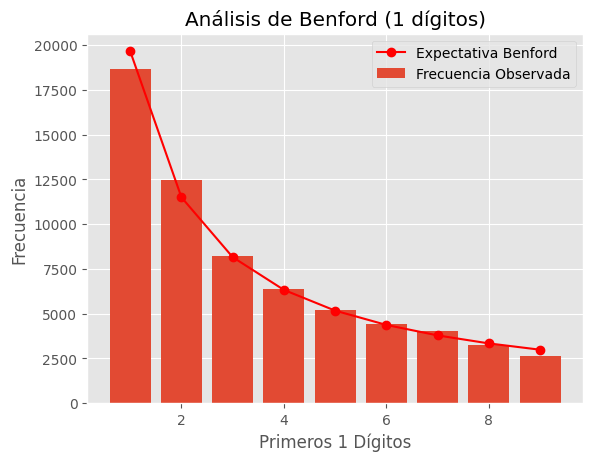

La distribución observada se desvía de la Ley de Benford. Puede requerir una revisión adicional.


,Primer Dígito,Frecuencia Observada,Expectativa Benford
1,1,18655,19655.75
2,2,12481,11497.88
3,3,8204,8157.87
4,4,6378,6327.74
5,5,5196,5170.14
6,6,4450,4371.29
7,7,4005,3786.58
8,8,3275,3340.0
9,9,2650,2987.74


In [15]:
benford_analysis(datos['NETO'], num_digits=1)

### Conclusión

Comparé los resultados obtenidos con este código y son exactamente iguales que los que se obtienen con ACL, solo habría que hacer un pequeño arreglo al realizar un análisis con 2 dígitos significativos, por lo demás es bastante alcanzable descubrir posibles casos para investigar usando el análisis Benford, el cuál no es por sí solo un sinónimo de fraude, pero sí un buen indicador de que algo ha ocurrido al encontrar desviaciones contra las cifras esperadas por la Ley.